<a href="https://colab.research.google.com/github/nageshappe/2048/blob/master/XAiPomegranateipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install kaggle tensorflow scikit-learn matplotlib seaborn split-folders shap

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"appenagesh","key":"fd885e4d20c6cc082855914df1f06a5d"}'}

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d sujaykapadnis/pomegranate-fruit-diseases-dataset
!unzip pomegranate-fruit-diseases-dataset.zip -d dataset

Dataset URL: https://www.kaggle.com/datasets/sujaykapadnis/pomegranate-fruit-diseases-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
 22% 952M/4.18G [00:13<00:47, 74.3MB/s]
User cancelled operation
Archive:  pomegranate-fruit-diseases-dataset.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of pomegranate-fruit-diseases-dataset.zip or
        pomegranate-fruit-diseases-dataset.zip.zip, and cannot find pomegranate-fruit-diseases-dataset.zip.ZIP, period.


### Download and Extract Dataset to Google Drive

I will re-attempt to download and extract the dataset. After successful extraction, the `dataset` folder will be moved to your Google Drive to ensure persistence and accessibility.

In [ ]:
# Re-download the dataset. Please wait for this to complete fully.
!kaggle datasets download -d sujaykapadnis/pomegranate-fruit-diseases-dataset -p /content/dataset_download

# Unzip the dataset into the 'dataset' directory
!unzip /content/dataset_download/pomegranate-fruit-diseases-dataset.zip -d /content/dataset

# Move the extracted dataset to Google Drive
!mv /content/dataset /content/drive/MyDrive/pomegranate_fruit_diseases_dataset

print("Dataset downloaded, extracted, and moved to Google Drive at '/content/drive/MyDrive/pomegranate_fruit_diseases_dataset'")

Streaming output truncated to the last 5000 lines.
  inflating: /content/dataset/Pomegranate Fruit Diseases Dataset for Deep Learning Models/Pomegranate Diseases Dataset/Pomegranate Diseases Dataset/Alternaria/IMG_20230916_113711_1.jpg  
  inflating: /content/dataset/Pomegranate Fruit Diseases Dataset for Deep Learning Models/Pomegranate Diseases Dataset/Pomegranate Diseases Dataset/Alternaria/IMG_20230916_113720_1.jpg  
  inflating: /content/dataset/Pomegranate Fruit Diseases Dataset for Deep Learning Models/Pomegranate Diseases Dataset/Pomegranate Diseases Dataset/Alternaria/IMG_20230916_113722_1.jpg  
  inflating: /content/dataset/Pomegranate Fruit Diseases Dataset for Deep Learning Models/Pomegranate Diseases Dataset/Pomegranate Diseases Dataset/Alternaria/IMG_20230916_113724.jpg  
  inflating: /content/dataset/Pomegranate Fruit Diseases Dataset for Deep Learning Models/Pomegranate Diseases Dataset/Pomegranate Diseases Dataset/Alternaria/IMG_20230916_113736.jpg  
  inflating: /cont

In [ ]:
import splitfolders

splitfolders.ratio(
    "dataset",
    output="split_data",
    seed=42,
    ratio=(0.7,0.15,0.15)
)

Copying files: 5099 files [00:45, 112.38 files/s]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import shap

In [ ]:
IMG_SIZE = (224,224)
BATCH = 16

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/split_data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/split_data/val",
    image_size=IMG_SIZE,
    batch_size=BATCH
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/split_data/test",
    image_size=IMG_SIZE,
    batch_size=BATCH,
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)

Found 3567 files belonging to 5 classes.
Found 761 files belonging to 5 classes.
Found 771 files belonging to 5 classes.
['Alternaria', 'Anthracnose', 'Bacterial_Blight', 'Cercospora', 'Healthy']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
def ARDAFM(x):

    c = x.shape[-1]

    avg = layers.GlobalAveragePooling2D()(x)

    dense1 = layers.Dense(c//8, activation='relu')(avg)
    dense2 = layers.Dense(c, activation='sigmoid')(dense1)

    # Correctly reshape to (batch_size, 1, 1, c) instead of (1, 1, c)
    dense2 = tf.expand_dims(tf.expand_dims(dense2, 1), 1)

    channel = layers.Multiply()([x,dense2])

    # Use tf.keras.layers.Lambda for mean and max operations
    avg_sp = layers.Lambda(lambda y: tf.reduce_mean(y, axis=-1, keepdims=True))(channel)
    max_sp = layers.Lambda(lambda y: tf.reduce_max(y, axis=-1, keepdims=True))(channel)

    spatial = layers.Concatenate()([avg_sp,max_sp])

    spatial = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(spatial)

    spatial_out = layers.Multiply()([channel, spatial])

    fused = layers.Add()([channel, spatial_out, x])

    return fused

In [ ]:
from tensorflow.keras import layers
import tensorflow as tf

# These custom layers are required for loading the previously saved model
# (which was saved before they were replaced by tf.keras.layers.Lambda in ARDAFM).
# They are included here to make the saved model loadable with `custom_objects`.
class MeanLayer(layers.Layer):
    def __init__(self, axis=None, keepdims=False, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis
        self.keepdims = keepdims

    def call(self, inputs):
        return tf.reduce_mean(inputs, axis=self.axis, keepdims=self.keepdims)

class MaxLayer(layers.Layer):
    def __init__(self, axis=None, keepdims=False, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis
        self.keepdims = keepdims

    def call(self, inputs):
        return tf.reduce_max(inputs, axis=self.axis, keepdims=self.keepdims)


In [ ]:
from tensorflow.keras import layers
import tensorflow as tf

# These custom layers are required for loading the previously saved model
# (which was saved before they were replaced by tf.keras.layers.Lambda in ARDAFM).
# They are included here to make the saved model loadable.
class MeanLayer(layers.Layer):
    def __init__(self, axis=None, keepdims=False, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis
        self.keepdims = keepdims

    def call(self, inputs):
        return tf.reduce_mean(inputs, axis=self.axis, keepdims=self.keepdims)

class MaxLayer(layers.Layer):
    def __init__(self, axis=None, keepdims=False, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis
        self.keepdims = keepdims

    def call(self, inputs):
        return tf.reduce_max(inputs, axis=self.axis, keepdims=self.keepdims)


In [ ]:
def build_model():

    inputs = tf.keras.Input(shape=(224,224,3))

    # Use ResNet50's preprocessing function
    x = tf.keras.applications.efficientnet.preprocess_input(inputs)

    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.25),
        layers.RandomZoom(0.25),
        layers.RandomContrast(0.3)
    ])

    x = aug(x)

    # Change base model to ResNet50
    base = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet'
    )

    base.trainable = False

    x = base(x)

    x = ARDAFM(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(5, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)

    return model

In [ ]:
model=build_model()

model.summary()
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ sequential[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 160)       │    204,960 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1280)      │    206,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1,      │          0 │ dense_1[0][0]     │
│                     │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 7, 7,      │          0 │ efficientnetb0[0… │
│                     │ 1280)             │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean_layer          │ (None, 7, 7, 1)   │          0 │ multiply[0][0]    │
│ (MeanLayer)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_layer           │ (None, 7, 7, 1)   │          0 │ multiply[0][0]    │
│ (MaxLayer)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 7, 7, 2)   │          0 │ mean_layer[0][0], │
│ (Concatenate)       │                   │            │ max_layer[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 7, 7, 1)   │         99 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 7, 7,      │          0 │ multiply[0][0],   │
│ (Multiply)          │ 1280)             │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 7, 7,      │          0 │ multiply[0][0],   │
│                     │ 1280)             │            │ multiply_1[0][0], │
│                     │                   │            │ efficientnetb0[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ add[0][0]         │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 5)         │      6,405 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,467,115 (17.04 MB)

 Trainable params: 417,544 (1.59 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25
)

Epoch 1/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 144s 646ms/step - accuracy: 0.5262 - loss: 1.2435 - val_accuracy: 0.6728 - val_loss: 1.0183
Epoch 2/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 156s 700ms/step - accuracy: 0.5921 - loss: 1.1187 - val_accuracy: 0.7162 - val_loss: 0.8952
Epoch 3/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 158s 711ms/step - accuracy: 0.6526 - loss: 0.9907 - val_accuracy: 0.7516 - val_loss: 0.7887
Epoch 4/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 186s 637ms/step - accuracy: 0.6888 - loss: 0.9002 - val_accuracy: 0.7845 - val_loss: 0.6975
Epoch 5/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 170s 765ms/step - accuracy: 0.7393 - loss: 0.7922 - val_accuracy: 0.8095 - val_loss: 0.6183
Epoch 6/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 155s 696ms/step - accuracy: 0.7592 - loss: 0.7318 - val_accuracy: 0.8305 - val_loss: 0.5507
Epoch 7/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 145s 649ms/step - accuracy: 0.7895 - loss: 0.6611 - val_accuracy: 0.8541 - val_loss: 0.4926
Epoch 8/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 200s 640ms/step - accuracy: 0.7998 -

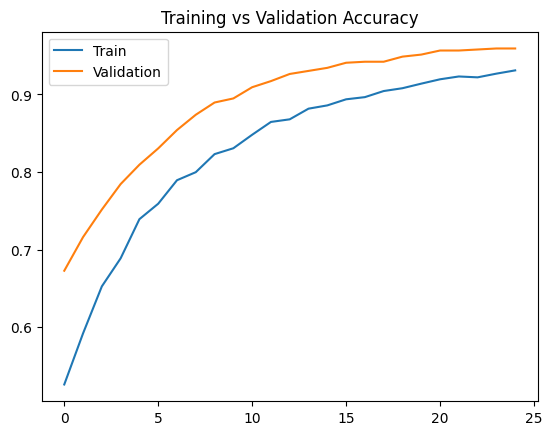

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.legend(['Train','Validation'])
plt.title("Training vs Validation Accuracy")
plt.show()

In [ ]:
loss, acc = model.evaluate(test_ds)

print("Test Accuracy:", acc*100)

49/49 ━━━━━━━━━━━━━━━━━━━━ 27s 549ms/step - accuracy: 0.9559 - loss: 0.1574
Test Accuracy: 95.59014439582825


In [ ]:
y_true = np.concatenate([y for x,y in test_ds], axis=0)

preds = model.predict(test_ds)
y_pred = np.argmax(preds, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

49/49 ━━━━━━━━━━━━━━━━━━━━ 27s 458ms/step
                  precision    recall  f1-score   support

      Alternaria       0.94      0.99      0.96       134
     Anthracnose       0.95      0.94      0.95       176
Bacterial_Blight       0.95      0.97      0.96       146
      Cercospora       0.94      0.82      0.88        96
         Healthy       0.98      1.00      0.99       219

        accuracy                           0.96       771
       macro avg       0.95      0.94      0.95       771
    weighted avg       0.96      0.96      0.96       771



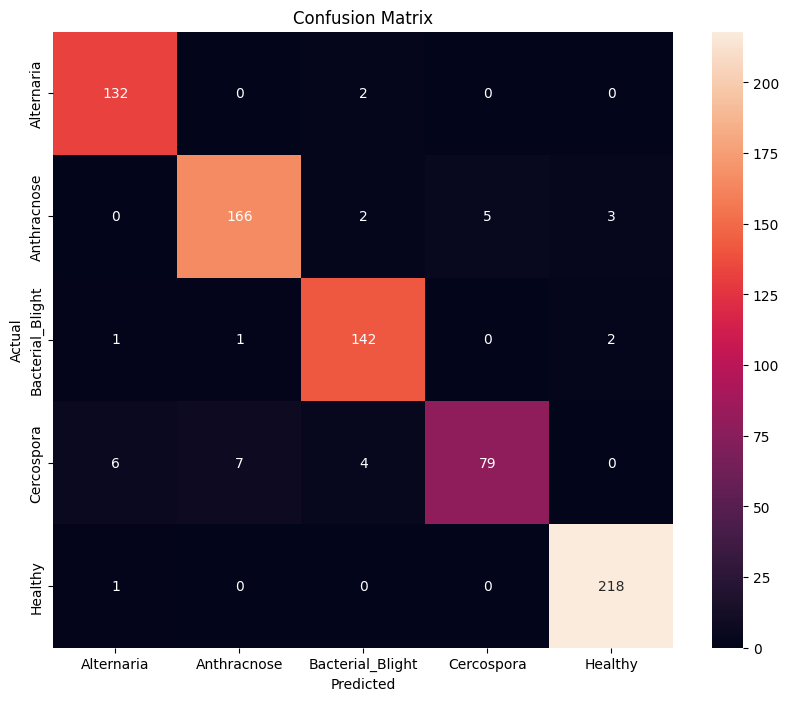

In [ ]:
cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Last Conv Layer: add
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
True Class : Alternaria
Predicted  : Alternaria


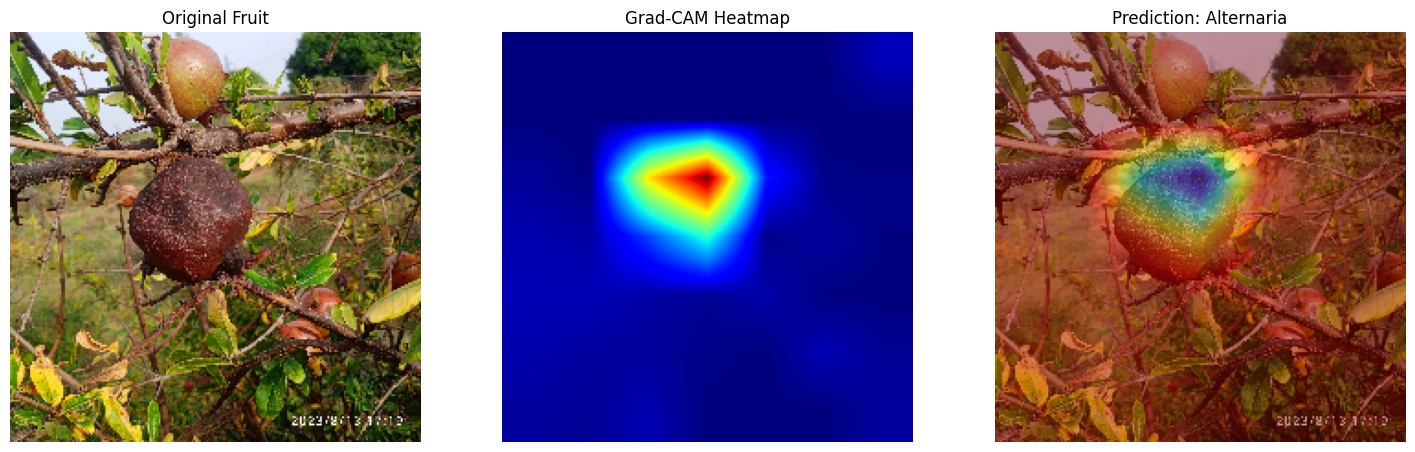

Saved as gradcam_result.png


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os


# =====================================
# 1. Find Last Convolution Layer
# =====================================

last_conv_layer_name = None

for layer in reversed(model.layers):
    if len(layer.output.shape) == 4:
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer:", last_conv_layer_name)


# =====================================
# 2. Build Grad-CAM Model
# =====================================

grad_model = tf.keras.models.Model(
    inputs=model.input,
    outputs=[
        model.get_layer(last_conv_layer_name).output,
        model.output
    ]
)


# =====================================
# 3. Get Sample Test Image
# =====================================

for images, labels in test_ds.take(1):
    img = images[0]
    true_label = labels[0]
    break

img_batch = tf.expand_dims(img, axis=0)


# =====================================
# 4. Prediction
# =====================================

predictions = model.predict(img_batch)

predicted_class = np.argmax(predictions[0])

print("True Class :", class_names[true_label])
print("Predicted  :", class_names[predicted_class])


# =====================================
# 5. Compute Gradients
# =====================================

with tf.GradientTape() as tape:

    conv_outputs, preds = grad_model(img_batch)

    loss = preds[:, predicted_class]

grads = tape.gradient(loss, conv_outputs)


# =====================================
# 6. Compute Heatmap
# =====================================

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

heatmap = tf.squeeze(heatmap)

heatmap = tf.maximum(heatmap, 0)

heatmap /= tf.math.reduce_max(heatmap)

heatmap = heatmap.numpy()


# =====================================
# 7. Convert Image for Display
# =====================================

img_np = img.numpy()

if img_np.max() <= 1:
    img_np = (img_np * 255).astype("uint8")
else:
    img_np = img_np.astype("uint8")


# =====================================
# 8. Resize Heatmap
# =====================================

heatmap = cv2.resize(heatmap, (224,224))

heatmap = np.uint8(255 * heatmap)

heatmap_color = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)


# =====================================
# 9. Overlay Heatmap
# =====================================

superimposed_img = cv2.addWeighted(
    img_np,
    0.6,
    heatmap_color,
    0.4,
    0
)


# =====================================
# 10. Display Results
# =====================================

plt.figure(figsize=(18,6))

# Original
plt.subplot(1,3,1)
plt.imshow(img_np)
plt.title("Original Fruit")
plt.axis("off")

# Heatmap
plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM Heatmap")
plt.axis("off")

# Overlay
plt.subplot(1,3,3)
plt.imshow(superimposed_img)
plt.title(f"Prediction: {class_names[predicted_class]}")
plt.axis("off")

plt.show()


# =====================================
# 11. Save for Paper
# =====================================

cv2.imwrite(
    "gradcam_result.png",
    cv2.cvtColor(superimposed_img, cv2.COLOR_RGB2BGR)
)

print("Saved as gradcam_result.png")

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image

# Upload image
uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(
    img_path,
    target_size=(224,224)
)

# Convert to array
img_array = image.img_to_array(img)

# Save original for display
img_display = img_array.astype("uint8")

# Expand dimensions
img_batch = np.expand_dims(img_array, axis=0)

# Preprocess for model
img_batch = tf.keras.applications.efficientnet.preprocess_input(img_batch)

Saving IMG_20230813_151728_1.jpg to IMG_20230813_151728_1.jpg


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os


# =====================================
# 1. Find Last Convolution Layer
# =====================================

last_conv_layer_name = None

for layer in reversed(model.layers):
    if len(layer.output.shape) == 4:
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer:", last_conv_layer_name)


# =====================================
# 2. Build Grad-CAM Model
# =====================================

grad_model = tf.keras.models.Model(
    inputs=model.input,
    outputs=[
        model.get_layer(last_conv_layer_name).output,
        model.output
    ]
)
from google.colab import files
from tensorflow.keras.preprocessing import image

# Upload image
uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(
    img_path,
    target_size=(224,224)
)

# Convert to array
img_array = image.img_to_array(img)

# Save original for display
img_display = img_array.astype("uint8")

# Expand dimensions
img_batch = np.expand_dims(img_array, axis=0)

# Preprocess for model
img_batch = tf.keras.applications.efficientnet.preprocess_input(img_batch)
# =====================================
# 4. Prediction
# =====================================

predictions = model.predict(img_batch)
true_label= 2
predicted_class = np.argmax(predictions[0])

print("True Class :", class_names[true_label])
print("Predicted  :", class_names[predicted_class])


# =====================================
# 5. Compute Gradients
# =====================================

with tf.GradientTape() as tape:

    conv_outputs, preds = grad_model(img_batch)

    loss = preds[:, predicted_class]

grads = tape.gradient(loss, conv_outputs)


# =====================================
# 6. Compute Heatmap
# =====================================

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

heatmap = tf.squeeze(heatmap)

heatmap = tf.maximum(heatmap, 0)

heatmap /= tf.math.reduce_max(heatmap)

heatmap = heatmap.numpy()


# =====================================
# 7. Convert Image for Display
# =====================================

img_np = img_display # Use the already prepared NumPy array

if img_np.max() <= 1:
    img_np = (img_np * 255).astype("uint8")
else:
    img_np = img_np.astype("uint8")


# =====================================
# 8. Resize Heatmap
# =====================================

heatmap = cv2.resize(heatmap, (224,224))

heatmap = np.uint8(255 * heatmap)

heatmap_color = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)


# =====================================
# 9. Overlay Heatmap
# =====================================

superimposed_img = cv2.addWeighted(
    img_np,
    0.6,
    heatmap_color,
    0.4,
    0
)


# =====================================
# 10. Display Results
# =====================================

plt.figure(figsize=(18,6))

# Original
plt.subplot(1,3,1)
plt.imshow(img_np)
plt.title(f"Original Fruit:{class_names[true_label]}")
plt.axis("off")

# Heatmap
plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM Heatmap")
plt.axis("off")

# Overlay
plt.subplot(1,3,3)
plt.imshow(superimposed_img)
plt.title(f"Prediction: {class_names[predicted_class]}")
plt.axis("off")

plt.show()


# =====================================
# 11. Save for Paper
# =====================================

cv2.imwrite(
    "gradcam_result.png",
    cv2.cvtColor(superimposed_img, cv2.COLOR_RGB2BGR)
)

print("Saved as gradcam_result1.png")

NameError: name 'model' is not defined

In [ ]:
import tensorflow as tf
import numpy as np

# ==========================================
# Attention Visualization
# ==========================================

attention_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.layers[-4].output
)

attention_maps = attention_model.predict(img_batch)

attention_map = np.mean(
    attention_maps[0],
    axis=-1
)

attention_map -= attention_map.min()
attention_map /= attention_map.max()

In [ ]:
model.save("xai_pomegrante.h5")

In [ ]:
import tensorflow as tf
import numpy as np

# Select a sample image from the test dataset for inference demonstration
for images, labels in test_ds.take(1):
    img = images[0]
    true_label = labels[0]
    break

# Expand dimensions to create a batch of one image
img_batch = tf.expand_dims(img, axis=0)

# Make a prediction with the loaded model
predictions_loaded = loaded_model.predict(img_batch)
predicted_class_loaded = np.argmax(predictions_loaded[0])

print(f"\nSelected image belongs to class: {class_names[true_label]}")
print(f"Prediction with loaded model: {class_names[predicted_class_loaded]}")

NameError: name 'test_ds' is not defined

In [ ]:
# Ensure class_names, IMG_SIZE, and BATCH are defined for subsequent cells.
# These values are usually derived from the dataset loading step.
class_names = ['Alternaria', 'Anthracnose', 'Bacterial_Blight', 'Cercospora', 'Healthy']
IMG_SIZE = (224, 224)
BATCH = 16

In [ ]:
import tensorflow as tf
import numpy as np

# Define the custom objects for loading the model. `ARDAFM` should be defined in a prior cell.
custom_objects = {
    'ARDAFM': ARDAFM,
    'MeanLayer': MeanLayer,
    'MaxLayer': MaxLayer
}

# Load the saved model with custom objects
loaded_model = tf.keras.models.load_model('xai_pomegrante.h5', custom_objects=custom_objects)

print("Model loaded successfully!")
loaded_model.summary()

Model loaded successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ sequential[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 160)       │    204,960 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1280)      │    206,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1,      │          0 │ dense_1[0][0]     │
│                     │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 7, 7,      │          0 │ efficientnetb0[0… │
│                     │ 1280)             │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean_layer          │ (None, 7, 7, 1)   │          0 │ multiply[0][0]    │
│ (MeanLayer)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_layer           │ (None, 7, 7, 1)   │          0 │ multiply[0][0]    │
│ (MaxLayer)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 7, 7, 2)   │          0 │ mean_layer[0][0], │
│ (Concatenate)       │                   │            │ max_layer[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 7, 7, 1)   │         99 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 7, 7,      │          0 │ multiply[0][0],   │
│ (Multiply)          │ 1280)             │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 7, 7,      │          0 │ multiply[0][0],   │
│                     │ 1280)             │            │ multiply_1[0][0], │
│                     │                   │            │ efficientnetb0[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ add[0][0]         │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 5)         │      6,405 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,467,117 (17.04 MB)

 Trainable params: 417,544 (1.59 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

 Optimizer params: 2 (12.00 B)

Please upload an image for prediction:


Saving BacterialBlight.jpg to BacterialBlight.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

Uploaded image: BacterialBlight.jpg
Predicted class: Bacterial_Blight with 97.07% confidence.


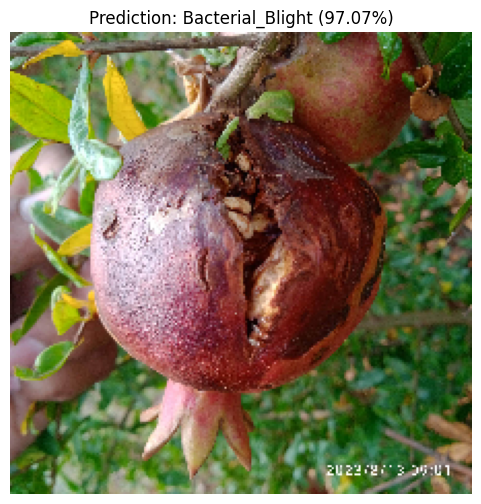

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Upload image
print("Please upload an image for prediction:")
uploaded = files.upload()

# Get the path of the uploaded image
img_path = list(uploaded.keys())[0]

# Load and preprocess the image
img = image.load_img(
    img_path,
    target_size=IMG_SIZE
)

img_array = image.img_to_array(img)
img_display_uploaded = img_array.astype("uint8") # For displaying later
img_batch_uploaded = np.expand_dims(img_array, axis=0)

# Preprocess the image using the same method as the model's training
img_batch_uploaded = tf.keras.applications.efficientnet.preprocess_input(img_batch_uploaded)

# Make prediction with the loaded model
predictions_unseen = loaded_model.predict(img_batch_uploaded)
predicted_class_unseen = np.argmax(predictions_unseen[0])
predicted_probability_unseen = np.max(predictions_unseen[0]) * 100

print(f"\nUploaded image: {img_path}")
print(f"Predicted class: {class_names[predicted_class_unseen]} with {predicted_probability_unseen:.2f}% confidence.")

# Display the uploaded image with its prediction
plt.figure(figsize=(6, 6))
plt.imshow(img_display_uploaded)
plt.title(f"Prediction: {class_names[predicted_class_unseen]} ({predicted_probability_unseen:.2f}%)")
plt.axis("off")
plt.show()

Last Conv Layer: add


Saving BacterialBlight.jpg to BacterialBlight (1).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
True Class : Bacterial_Blight
Predicted  : Bacterial_Blight


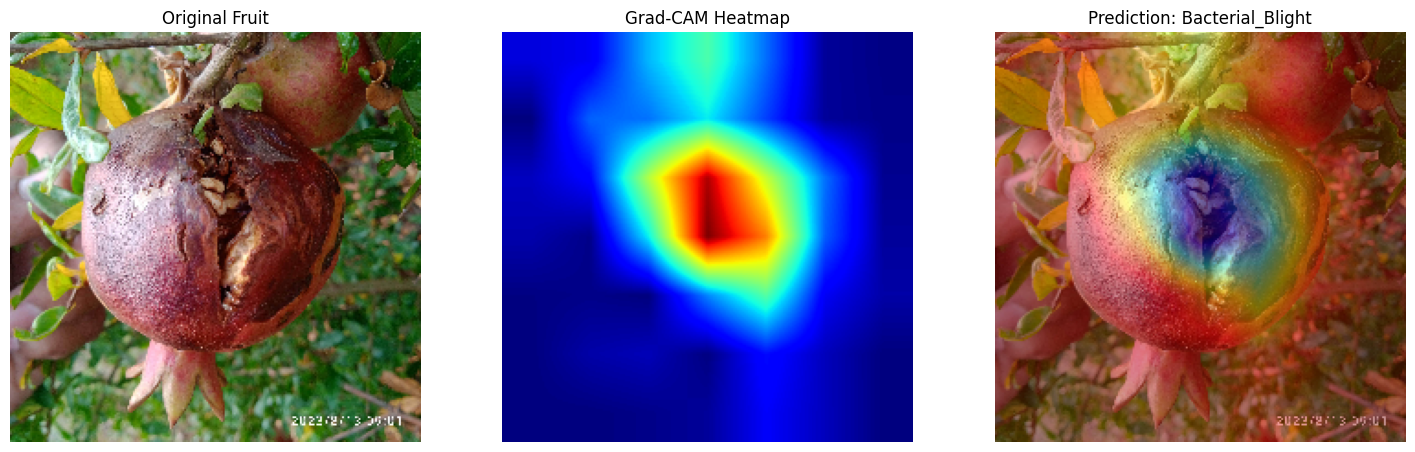

Saved as gradcam_result.png


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os


# =====================================
# 1. Find Last Convolution Layer
# =====================================

last_conv_layer_name = None

for layer in reversed(loaded_model.layers):
    if len(layer.output.shape) == 4:
        last_conv_layer_name = layer.name
        break

print("Last Conv Layer:", last_conv_layer_name)


# =====================================
# 2. Build Grad-CAM Model
# =====================================

grad_model = tf.keras.models.Model(
    inputs=loaded_model.input,
    outputs=[
        loaded_model.get_layer(last_conv_layer_name).output,
        loaded_model.output
    ]
)


# =====================================
# 3. Get Sample Test Image
# =====================================


from google.colab import files
from tensorflow.keras.preprocessing import image

# Upload image
uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(
    img_path,
    target_size=(224,224)
)

# Convert to array
img_array = image.img_to_array(img)

# Save original for display
img_display = img_array.astype("uint8")


img_batch = tf.expand_dims(img, axis=0)

# Choose one depending on your model
img_batch = tf.keras.applications.efficientnet.preprocess_input(img_batch)
# =====================================
# 4. Prediction
# =====================================

predictions = loaded_model.predict(img_batch)

predicted_class = np.argmax(predictions[0])
true_label=2
print("True Class :", class_names[true_label])
print("Predicted  :", class_names[predicted_class])


# =====================================
# 5. Compute Gradients
# =====================================

with tf.GradientTape() as tape:

    conv_outputs, preds = grad_model(img_batch)

    loss = preds[:, predicted_class]

grads = tape.gradient(loss, conv_outputs)


# =====================================
# 6. Compute Heatmap
# =====================================

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

heatmap = tf.squeeze(heatmap)

heatmap = tf.maximum(heatmap, 0)

heatmap /= tf.math.reduce_max(heatmap)

heatmap = heatmap.numpy()


# =====================================
# 7. Convert Image for Display
# =====================================

img_np = img_display # Use the already prepared NumPy array

if img_np.max() <= 1:
    img_np = (img_np * 255).astype("uint8")
else:
    img_np = img_np.astype("uint8")




# =====================================
# 8. Resize Heatmap
# =====================================

heatmap = cv2.resize(heatmap, (224,224))

heatmap = np.uint8(255 * heatmap)

heatmap_color = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)


# =====================================
# 9. Overlay Heatmap
# =====================================

superimposed_img = cv2.addWeighted(
    img_np,
    0.6,
    heatmap_color,
    0.4,
    0
)


# =====================================
# 10. Display Results
# =====================================

plt.figure(figsize=(18,6))

# Original
plt.subplot(1,3,1)
plt.imshow(img_np)
plt.title("Original Fruit")
plt.axis("off")

# Heatmap
plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM Heatmap")
plt.axis("off")

# Overlay
plt.subplot(1,3,3)
plt.imshow(superimposed_img)
plt.title(f"Prediction: {class_names[predicted_class]}")
plt.axis("off")

plt.show()


# =====================================
# 11. Save for Paper
# =====================================

cv2.imwrite(
    "gradcam_result.png",
    cv2.cvtColor(superimposed_img, cv2.COLOR_RGB2BGR)
)

print("Saved as gradcam_result.png")